# CSC14120 – Panorama Image Stitching
## Nhóm 22 · Báo cáo giữa kỳ: V0 và kế hoạch CUDA
Báo cáo phần hệ thống, dữ liệu và profiling của thành viên 3. Chương trình C++ được biên dịch trực tiếp từ `src/`. Số liệu và hình bên dưới được sinh bởi các cell, không điền thủ công.

**Trạng thái:** đã thực thi trên máy Windows bằng g++; cần chạy lại trên Colab để xác nhận môi trường Colab. Cặp synthetic hiện dùng là fixture tự sinh, chưa phải cặp chính thức của môn học. Link Drive do nhóm cung cấp; chưa xác minh quyền truy cập công khai.

## 0. Setup
Local: mở notebook trong thư mục dự án. Colab: giải nén `Group22_Midterm.zip` và `Group22_Dataset.zip` cùng vào `/content/Group22_Midterm`, hoặc đặt `src/`, `tools/`, `team.json`, `requirements.txt`, `dataset/` trong thư mục Drive cấu hình bên dưới. Dataset được chia sẻ tại [Google Drive của nhóm](https://drive.google.com/drive/folders/1tAZe8d2SR47yGxrKt7KvgJqyN25M6P1X?usp=sharing).


In [1]:
from pathlib import Path
import os, sys, shutil, subprocess, json
IN_COLAB = 'google.colab' in sys.modules
DRIVE_PROJECT = '/content/drive/MyDrive/Group22_Midterm'  # sửa theo thư mục Drive thực tế
if IN_COLAB:
    ROOT = Path('/content/Group22_Midterm')
    if not (ROOT/'src').exists():
        from google.colab import drive
        drive.mount('/content/drive')
        source = Path(DRIVE_PROJECT)
        assert (source/'src').is_dir(), f'Chưa có src tại {source}; giải nén gói hoặc sửa DRIVE_PROJECT.'
        ROOT.mkdir(parents=True, exist_ok=True)
        for name in ['src', 'tools', 'dataset']:
            if (source/name).exists():
                shutil.copytree(source/name, ROOT/name, dirs_exist_ok=True)
        for name in ['team.json', 'requirements.txt']:
            shutil.copy2(source/name, ROOT/name)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                    'numpy', 'Pillow', 'pillow-heif', 'matplotlib'], check=True)
else:
    ROOT = Path.cwd().resolve()
assert (ROOT/'src/main.cu').exists(), 'Mở notebook tại thư mục chứa src/'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT/'.tools'))
sys.path.insert(0, str(ROOT/'tools'))
from build import build
binary, build_command = build(ROOT)
print('Binary:', binary)
print('Build command:', ' '.join(build_command))
print('Compiler:', subprocess.check_output([build_command[0], '--version'], text=True).splitlines()[0])
(ROOT/'outputs_v0').mkdir(exist_ok=True)
team = json.loads((ROOT/'team.json').read_text(encoding='utf-8-sig'))


[PROCESS]: C:\mingw64\bin\g++.EXE -O3 -std=c++14 -x c++ A:\PP\Midterm\src\main.cu A:\PP\Midterm\src\stb_impl.cpp A:\PP\Midterm\src\v0_frontend.cpp A:\PP\Midterm\src\v0_backend.cpp A:\PP\Midterm\src\v0_stitching.cpp -o A:\PP\Midterm\stitch.exe


Binary: A:\PP\Midterm\stitch.exe
Build command: C:\mingw64\bin\g++.EXE -O3 -std=c++14 -x c++ A:\PP\Midterm\src\main.cu A:\PP\Midterm\src\stb_impl.cpp A:\PP\Midterm\src\v0_frontend.cpp A:\PP\Midterm\src\v0_backend.cpp A:\PP\Midterm\src\v0_stitching.cpp -o A:\PP\Midterm\stitch.exe
Compiler: g++.EXE (MinGW-W64 x86_64-msvcrt-posix-seh, built by Brecht Sanders) 13.1.0


## 3.1 Thông tin nhóm và kế hoạch công việc

In [2]:
from report import table
table(['Thành viên', 'Họ tên', 'MSSV', 'Trách nhiệm V0'], [
    [m['role'], m['name'], m['student_id'],
     {1:'Backend: stages 4–6', 2:'Frontend: stages 1–3', 3:'System, data, profiling, notebook'}[m['role']]]
    for m in team['members']])
if not team.get('role_order_confirmed'):
    from console import log
    log('WARN', 'Vai trò thành viên chưa được xác nhận đầy đủ.')


| Thành viên | Họ tên | MSSV | Trách nhiệm V0 |
|---|---|---|---|
| 3 | Nguyễn Hữu Khánh Hưng | 23120271 | System, data, profiling, notebook |
| 2 | Vũ Trần Phúc | 23120333 | Frontend: stages 1–3 |
| 1 | Trần Nguyễn Minh Quân | 23120342 | Backend: stages 4–6 |

| Mốc | Thành viên 1 | Thành viên 2 | Thành viên 3 |
|---|---|---|---|
| Midterm / V0 | Matching, RANSAC, warp/blend | Gray/blur, FAST/NMS, BRIEF | CLI, dataset, correctness, profiling, notebook |
| V1 / tuần 8–9 | CUDA stages 4–6 | CUDA stages 1–3 | CUDA Events, đối chiếu V0, đo truyền dữ liệu |
| V2 / tuần 10 | Tiling matching, parallel RANSAC | Shared-memory blur, scan/compaction | Nsight, memory throughput, occupancy |
| V3 / tuần 11 | Texture sampling, blending | Hai stream frontend | Đo fusion, pinned memory và chi phí điều phối |
| Final / tuần 12–13 | Nội dung backend, slide/demo | Nội dung frontend, slide/demo | Tổng hợp báo cáo, đóng gói, video |


## 3.2 Hiểu bài toán
Hai ảnh A (left) và B (right) được chuyển xám và làm mịn, phát hiện góc FAST rồi mô tả bằng BRIEF. Matching tìm cặp đặc trưng theo khoảng cách Hamming và lọc bằng ratio test. RANSAC loại ngoại lai và ước lượng **H: B → A**. Warping ánh xạ ngược từ canvas về ảnh nguồn để nội suy và hòa trộn.

Homography mô hình hóa cảnh gần phẳng hoặc máy ảnh xoay quanh tâm chiếu; vật thể ở nhiều độ sâu và chuyển động có thể gây bóng kép. V0 hiện dùng trọng số 50/50 ở vùng chồng lấp nên còn đường nối. Nội dung stages 1–3 và 4–6 cần TV2/TV1 duyệt theo mã nguồn hiện tại.

## 3.3 Phương pháp và tham số thực sự đang dùng
| Stage | Cài đặt V0 / tham số | Chất lượng và hướng GPU |
|---|---|---|
| 1 | Rec.601; Gaussian tách rời 5×5, sigma 1.2; biên clamp | Giảm nhiễu; phép tính pixel phù hợp grid 2D |
| 2 | FAST-9, threshold 20; kiểm tra sớm 4 điểm; NMS 3×3 nghiêm ngặt; top 1500 | Giới hạn chi phí matching; top-K không bảo đảm phân bố đều; scan/NMS cần bước riêng trên GPU |
| 3 | BRIEF 256 bit/32 byte; patch 31×31; Gaussian sigma 6; seed 14120 | Nhỏ gọn; chưa bất biến góc xoay/tỷ lệ; biên ảnh hiện nhận descriptor zero |
| 4 | BF Hamming, ratio <0.75 | Loại bớt so khớp mơ hồ; không bảo đảm loại hết ngoại lai; dự kiến `__popc` |
| 5 | RANSAC 1500 lần, seed 42, ngưỡng 3 px; giải hệ 8×8 bằng khử Gauss | Chọn mô hình nhiều inlier nhất; **chưa refit toàn bộ inlier**; có thể song song giả thuyết |
| 6 | Inverse warp, bilinear, canvas bounding box, average 0.5/0.5 | Không phải feathering; mỗi pixel canvas có thể tính độc lập |

Các điểm cần TV1/TV2 cải thiện: refit H trên inliers, feathering thực sự, xử lý descriptor ở biên và kiểm tra FAST-9. Không gán các đặc tính chưa cài đặt cho V0.

## 3.4 Kiến trúc tuần tự V0
`common.h` chứa `ImageRGB`, `ImageGray`, `Keypoint`, `Descriptor256`, `Match`, `Homography3x3` và `StageTimings`. Ảnh RGB xen kẽ nằm trong vector sở hữu dữ liệu; descriptor gồm 32 byte, match lưu chỉ số để nối keypoint với descriptor; H là 9 số double row-major.

`versions.h` khai báo giao diện; `v0_stitching.cpp::run_v0` gọi lần lượt 6 stage từ `v0_frontend.cpp` và `v0_backend.cpp`. `main.cu` nạp ảnh một lần, chạy warmup và các lần đo rồi lưu panorama/H/CSV. `logging.h` dùng nhãn SUCCESS xanh, ERROR đỏ, WARN vàng, PROCESS trắng; `NO_COLOR` tắt ANSI khi cần log văn bản thuần. `cuda_utils.cuh` cung cấp kiểm tra lỗi và event timer cho V1, chưa được dùng để đo V0.

V0 đơn luồng, không OpenMP/std::thread hay SIMD tự viết. Mỗi stage 1–3 bao gồm cả hai ảnh. CPU timer dùng `high_resolution_clock`; total đo toàn pipeline và bao gồm điều phối/cấp phát nội bộ. Đọc/ghi ảnh, CSV, H và log thông thường nằm ngoài vùng đo. Một warmup bị loại; mọi thống kê dùng năm lần tiếp theo. Min tổng là min của total đo thực tế, không cộng các min stage.

**Nguồn mã:** `stb_image.h` và `stb_image_write.h` của Sean Barrett, [nothings/stb](https://github.com/nothings/stb), giấy phép lựa chọn MIT hoặc public domain, giữ nguyên license trong header. Các tiện ích hệ thống do nhóm viết. Các tài liệu FAST (Rosten & Drummond, 2006), BRIEF (Calonder et al., 2010), Lowe ratio (2004), RANSAC (Fischler & Bolles, 1981), Hartley & Zisserman (2003) là tham khảo thuật toán được ghi ở frontend/backend; cần tác giả các module xác nhận nếu có tái sử dụng mã từ nguồn khác.


## 3.5 Kết quả V0 và profiling
### Chuẩn bị dữ liệu và chạy thí nghiệm
Không ghi đè cặp synthetic đã cung cấp. Khi thiếu, sinh fixture dịch chuyển xác định để kiểm tra tích hợp; fixture này **không thay cho synthetic pair chính thức** nếu môn học yêu cầu cặp đó. Metadata và chiều H được lưu trong `provenance.json`.


In [3]:
from prepare_dataset import prepare, synthetic
expected = [ROOT/f'dataset/prepared/{res}/{site}_{side}.png'
            for res in ['small','medium','large']
            for site in ['site1_indoor','site2_outdoor','site3_custom','site4_challenging']
            for side in ['left','right']]
if not all(path.exists() for path in expected) or not (ROOT/'dataset/prepared/manifest.json').exists():
    prepare(ROOT)
required_synthetic = ['synthetic_left.png','synthetic_right.png','H_ground_truth.txt']
if not all((ROOT/'dataset/synthetic'/name).exists() for name in required_synthetic):
    print('[WARN]: Chưa có synthetic chính thức; dùng fixture tự sinh và ghi rõ provenance.')
    synthetic(ROOT)
from benchmark import benchmark
summary = benchmark(ROOT, runs=5, warmup=1)
summary['build_command'] = build_command
summary['compiler_version'] = subprocess.check_output([build_command[0], '--version'], text=True).splitlines()[0]
(ROOT/'outputs_v0/summary.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')
print('Machine:', summary['machine'], summary['processor'])
print('Measured at UTC:', summary['timestamp_utc'])
assert all(row['success'] for row in summary['results']), 'Có cặp thất bại; xem log trong outputs_v0/'


[PROCESS]: Benchmark small/site1_indoor


[PROCESS]: Benchmark small/site2_outdoor


[PROCESS]: Benchmark small/site3_custom


[PROCESS]: Benchmark small/site4_challenging


[PROCESS]: Benchmark medium/site1_indoor


...

[PROCESS]: Benchmark large/site2_outdoor


[PROCESS]: Benchmark large/site3_custom


[PROCESS]: Benchmark large/site4_challenging


[SUCCESS]: 12/12 successful real pairs


Machine: Windows-10-10.0.26200-SP0 Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
Measured at UTC: 2026-10-16T02:32:41.369363+00:00


### 3.5.1 Correctness
Chuẩn hóa H theo phần tử [2,2], tính Frobenius và sai số chiếu trên lưới điểm của ảnh B. Ngưỡng mean projection 1 px là tiêu chí kiểm thử nội bộ, không phải yêu cầu số học từ PDF. Kiểm thử dịch chuyển không chứng minh độ đúng với mọi phép biến đổi phối cảnh.


In [4]:
from report import show_correctness
show_correctness(summary)

**Synthetic provenance:** local_generated_translation_fixture

H estimated (B -> A):
 [[ 1.00000000e+00  1.01680619e-15  3.20000000e+02]
 [ 1.75252150e-15  1.00000000e+00 -2.70596235e-13]
 [ 5.05127115e-18  1.57240611e-18  1.00000000e+00]]
H ground truth (B -> A):
 [[  1.   0. 320.]
 [  0.   1.   0.]
 [  0.   0.   1.]]


| Metric | Measured value |
|---|---|
| Frobenius norm (H normalized by H[2,2]) | 3.534703e-13 |
| Mean projection error (px) | 3.344760e-13 |
| Max projection error (px) | 1.145451e-12 |
| Pass threshold (mean px) | 1.0 |
| Passed | True |

### 3.5.2 Panorama cho từng địa điểm
Ảnh đầu ra ở độ phân giải medium. Có vùng đen ngoài footprint ảnh sau warp. Còn đường nối, bóng kép và chênh lệch độ sáng: ảnh trong nhà dễ thấy trên cửa sổ/trần; cảnh cây xanh có cấu trúc lặp. Các ảnh này là đầu ra V0 thực tế, không xử lý hậu kỳ để che lỗi.


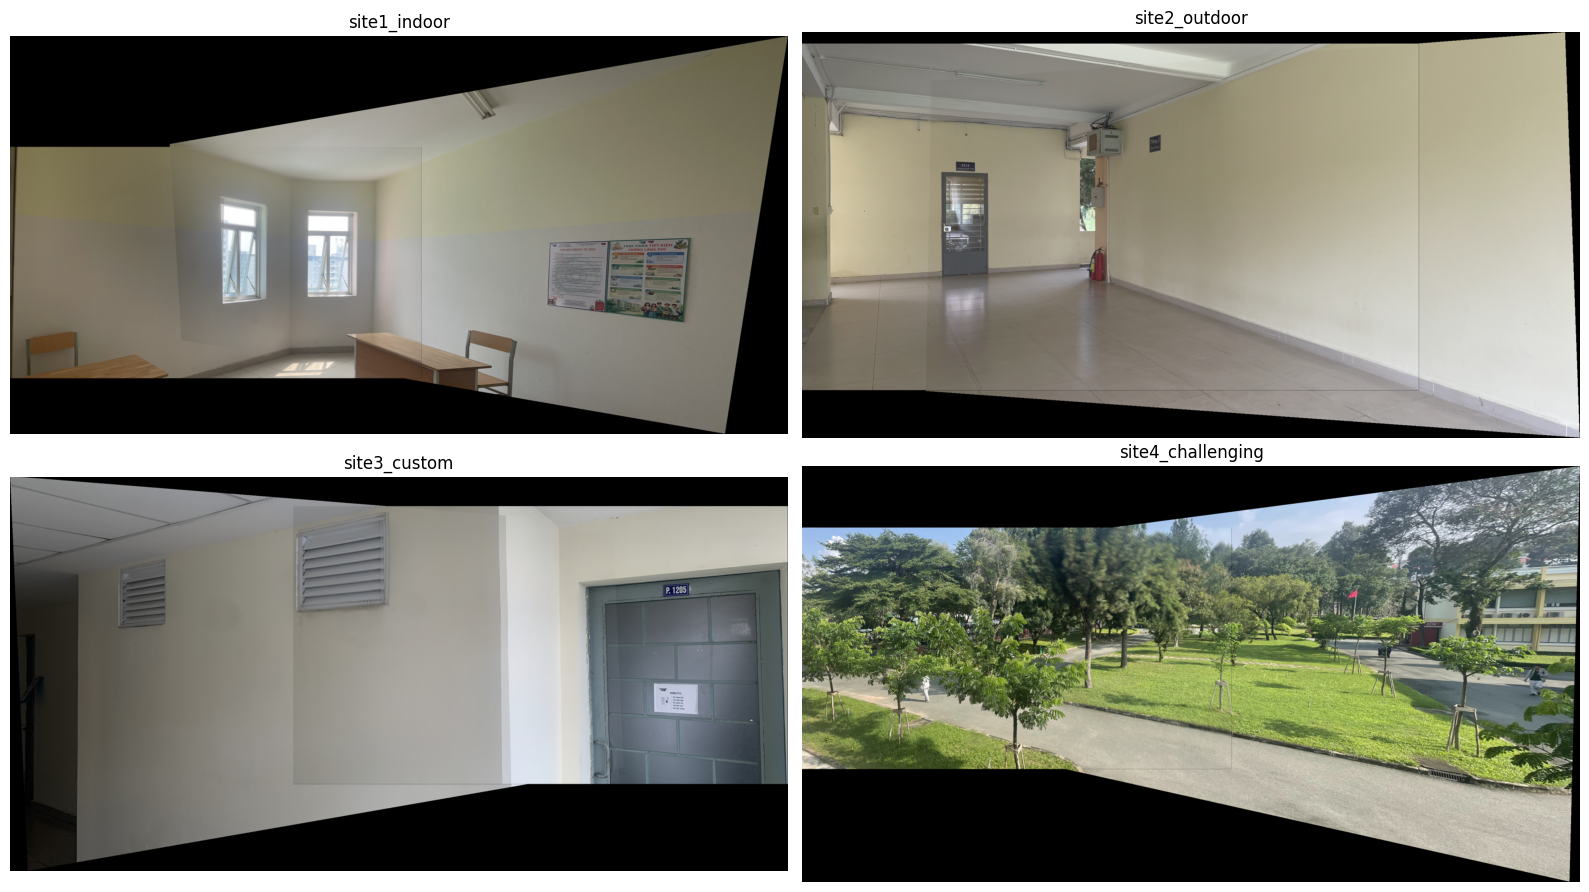

In [5]:
from report import show_panoramas
show_panoramas(ROOT)

### 3.5.3 Bảng thời gian và scaling
Bảng đầu thể hiện Mean/Min riêng từng site và độ phân giải. Bảng tổng hợp lấy trung bình đều bốn site; cột `mean(site min)` là trung bình các min theo site, không phải min toàn bộ thí nghiệm. CSV giữ đủ từng lần đo. Biểu đồ dùng thời gian trung bình bốn site; kích thước ảnh đầu ra có thể khác nhau theo H.


| Resolution | Site | Stage | Mean ms | Min ms |
|---|---|---|---|---|
| small | site1_indoor | 1 Preprocess | 15.376 | 14.928 |
| small | site1_indoor | 2 Keypoints | 9.885 | 9.322 |
| small | site1_indoor | 3 BRIEF | 0.388 | 0.343 |
| small | site1_indoor | 4 Matching | 1.280 | 1.228 |
| small | site1_indoor | 5 RANSAC | 0.785 | 0.772 |
| small | site1_indoor | 6 Warp/blend | 64.255 | 63.418 |
| small | site1_indoor | Total | 91.970 | 90.629 |
| small | site2_outdoor | 1 Preprocess | 16.198 | 15.691 |
| small | site2_outdoor | 2 Keypoints | 12.207 | 9.617 |
| small | site2_outdoor | 3 BRIEF | 0.616 | 0.548 |
| small | site2_outdoor | 4 Matching | 5.332 | 5.212 |
| small | site2_outdoor | 5 RANSAC | 1.439 | 1.411 |
| small | site2_outdoor | 6 Warp/blend | 37.930 | 37.337 |
| small | site2_outdoor | Total | 73.723 | 70.466 |
| small | site3_custom | 1 Preprocess | 15.504 | 14.742 |
| small | site3_custom | 2 Keypoints | 10.235 | 9.311 |
| small | site3_custom | 3 BRIEF | 0.319 | 0.272 |
| small | site3_custom | 4 Matching | 0.536 | 0.529 |
| small | site3_custom | 5 RANSAC | 0.528 | 0.509 |
| small | site3_custom | 6 Warp/blend | 43.629 | 42.954 |
| small | site3_custom | Total | 70.750 | 69.059 |
| small | site4_challenging | 1 Preprocess | 15.418 | 14.842 |
| small | site4_challenging | 2 Keypoints | 42.675 | 41.837 |
| small | site4_challenging | 3 BRIEF | 5.260 | 4.652 |
| small | site4_challenging | 4 Matching | 553.840 | 551.432 |
| small | site4_challenging | 5 RANSAC | 3.966 | 3.938 |
| small | site4_challenging | 6 Warp/blend | 56.040 | 55.112 |
| small | site4_challenging | Total | 677.201 | 673.871 |
| medium | site1_indoor | 1 Preprocess | 36.002 | 33.623 |
| medium | site1_indoor | 2 Keypoints | 22.066 | 21.402 |
| medium | site1_indoor | 3 BRIEF | 0.631 | 0.592 |
| medium | site1_indoor | 4 Matching | 3.389 | 3.267 |
| medium | site1_indoor | 5 RANSAC | 1.187 | 0.974 |
| medium | site1_indoor | 6 Warp/blend | 130.962 | 129.486 |
| medium | site1_indoor | Total | 194.239 | 191.946 |
| medium | site2_outdoor | 1 Preprocess | 35.675 | 34.080 |
| medium | site2_outdoor | 2 Keypoints | 25.340 | 22.391 |
| medium | site2_outdoor | 3 BRIEF | 1.265 | 1.169 |
| medium | site2_outdoor | 4 Matching | 24.276 | 22.744 |
| medium | site2_outdoor | 5 RANSAC | 2.494 | 2.229 |
| medium | site2_outdoor | 6 Warp/blend | 86.473 | 82.809 |
| medium | site2_outdoor | Total | 175.525 | 166.898 |
| medium | site3_custom | 1 Preprocess | 35.560 | 33.772 |
| medium | site3_custom | 2 Keypoints | 22.918 | 21.363 |
| medium | site3_custom | 3 BRIEF | 0.604 | 0.572 |
| medium | site3_custom | 4 Matching | 2.714 | 2.561 |
| medium | site3_custom | 5 RANSAC | 0.930 | 0.762 |
| medium | site3_custom | 6 Warp/blend | 108.687 | 104.757 |
| medium | site3_custom | Total | 171.413 | 164.702 |
| medium | site4_challenging | 1 Preprocess | 34.001 | 33.547 |
| medium | site4_challenging | 2 Keypoints | 121.628 | 115.696 |
| medium | site4_challenging | 3 BRIEF | 5.498 | 5.047 |
| medium | site4_challenging | 4 Matching | 559.460 | 556.109 |
| medium | site4_challenging | 5 RANSAC | 3.126 | 2.951 |
| medium | site4_challenging | 6 Warp/blend | 128.279 | 127.524 |
| medium | site4_challenging | Total | 851.994 | 844.900 |
| large | site1_indoor | 1 Preprocess | 138.458 | 135.490 |
| large | site1_indoor | 2 Keypoints | 91.601 | 86.123 |
| large | site1_indoor | 3 BRIEF | 1.737 | 1.658 |
| large | site1_indoor | 4 Matching | 22.114 | 21.102 |
| large | site1_indoor | 5 RANSAC | 1.385 | 1.163 |
| large | site1_indoor | 6 Warp/blend | 567.484 | 557.751 |
| large | site1_indoor | Total | 822.780 | 803.807 |
| large | site2_outdoor | 1 Preprocess | 137.604 | 135.986 |
| large | site2_outdoor | 2 Keypoints | 97.467 | 91.071 |
| large | site2_outdoor | 3 BRIEF | 3.909 | 3.176 |
| large | site2_outdoor | 4 Matching | 190.456 | 188.838 |
| large | site2_outdoor | 5 RANSAC | 4.708 | 4.394 |
| large | site2_outdoor | 6 Warp/blend | 352.802 | 350.163 |
| large | site2_outdoor | Total | 786.949 | 775.369 |
| large | site3_custom | 1 Preprocess | 137.049 | 135.486 |
| large | site3_custom | 2 Keypoints | 87.061 | 86.100 |
| large | site3_custom | 3 BRIEF | 2.184 | 1.784 |
| large | site3_custom | 4 Matching | 30.314 | 30.091 |
| large | site3_custom | 5 RANSAC | 1.192 | 1.125 |
| large | site3_custom | 6 Warp/blend | 440.179 | 437.302 |
| large | site3_custom | Total | 697.981 | 694.805 |
| large | site4_challenging | 1 Preprocess | 139.080 | 135.422 |
| large | site4_challenging | 2 Keypoints | 583.794 | 576.489 |
| large | site4_challenging | 3 BRIEF | 6.735 | 5.953 |
| large | site4_challenging | 4 Matching | 557.243 | 551.776 |
| large | site4_challenging | 5 RANSAC | 2.014 | 1.833 |
| large | site4_challenging | 6 Warp/blend | 512.155 | 507.175 |
| large | site4_challenging | Total | 1801.022 | 1786.989 |

| Stage | small mean / mean(site min), ms | medium mean / mean(site min), ms | large mean / mean(site min), ms |
|---|---|---|---|
| 1 Preprocess | 15.624 / 15.051 | 35.310 / 33.756 | 138.048 / 135.596 |
| 2 Keypoints | 18.751 / 17.522 | 47.988 / 45.213 | 214.981 / 209.946 |
| 3 BRIEF | 1.646 / 1.454 | 1.999 / 1.845 | 3.641 / 3.143 |
| 4 Matching | 140.247 / 139.600 | 147.460 / 146.170 | 200.032 / 197.952 |
| 5 RANSAC | 1.679 / 1.658 | 1.934 / 1.729 | 2.325 / 2.129 |
| 6 Warp/blend | 50.463 / 49.705 | 113.600 / 111.144 | 468.155 / 463.098 |
| Total | 228.411 / 226.006 | 348.293 / 342.112 | 1027.183 / 1015.242 |

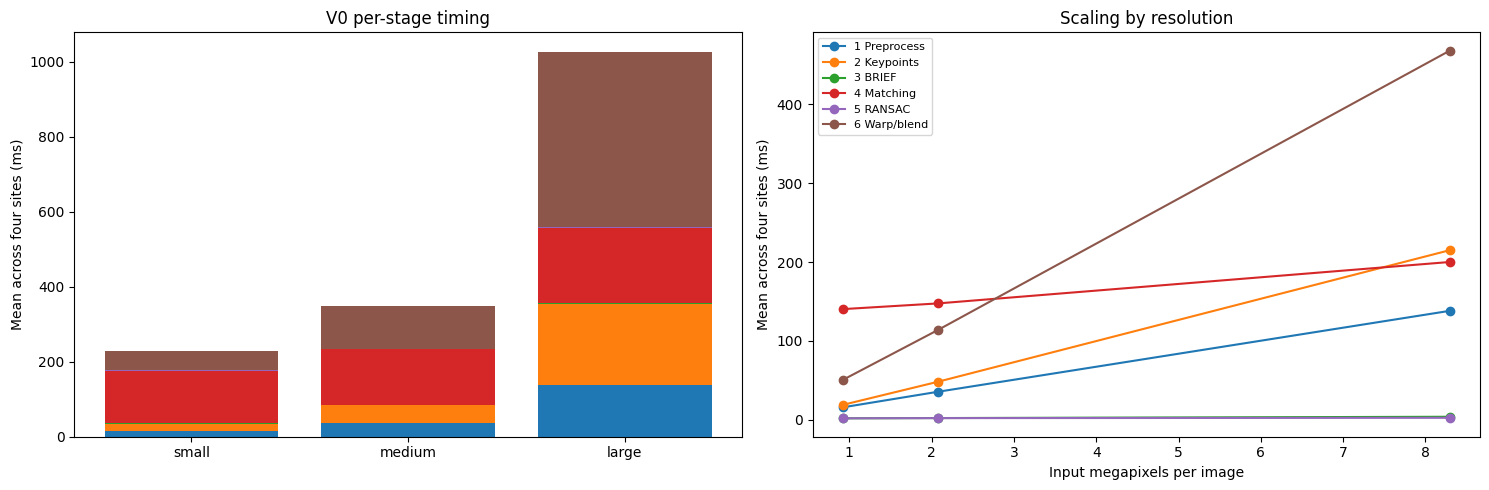

In [6]:
from report import show_timings
show_timings(summary, ROOT)

### 3.5.4 Hot stages và Amdahl
Chọn cả sáu stage cho V1 theo kế hoạch nhóm. Với từng độ phân giải, tính $p=\sum T_{GPU\ plan}/T_{pipeline}$ rồi $S_{max}=1/(1-p)$. Thứ hạng bottleneck được tính trực tiếp từ các kết quả đo; không giả định trước stage nào chậm nhất.


In [7]:
from report import show_analysis
show_analysis(summary)

| Resolution | Successful sites | Two hottest stages (% total) | p (planned six stages) | 1/(1-p), compute-only bound |
|---|---|---|---|---|
| small | 4 | matching_ms: 61.4%, warp_blend_ms: 22.1% | 0.99999586 | 241704.90x |
| medium | 4 | matching_ms: 42.3%, warp_blend_ms: 32.6% | 0.99999628 | 268952.13x |
| large | 4 | warp_blend_ms: 45.6%, keypoint_ms: 20.9% | 0.99999841 | 628246.55x |

Kế hoạch V1 chuyển cả sáu stage lên GPU. Các stage đứng đầu bảng được ưu tiên profiling và tối ưu. Tổng thời gian bao gồm điều phối/cấp phát trong pipeline, loại trừ đọc/ghi ảnh và log. Khi p gần 1, giới hạn Amdahl rất nhạy với phần thời gian điều phối nhỏ; đây là giới hạn lý thuyết cho **compute-only**, không phải dự báo speedup hay số đo GPU. Chi phí truyền H2D/D2H, launch và đồng bộ phải được đo ở V1.

## 3.6 Dataset
Link do nhóm cung cấp: [Google Drive dataset nhóm 22](https://drive.google.com/drive/folders/1tAZe8d2SR47yGxrKt7KvgJqyN25M6P1X?usp=sharing). Nhóm cần tải bộ prepared/synthetic đã tạo lên thư mục này và kiểm tra chế độ Anyone with the link.

Ảnh gốc là HEIC có tên không chuẩn phần mở rộng. Script nhận diện nội dung, áp dụng EXIF orientation, chuyển RGB, center-crop 16:9 rồi resize Lanczos thành ba cỡ. Ảnh gốc giữ nguyên. `manifest.json` ghi SHA256 nguồn, kích thước gốc, crop box và có/không upscale. Chú ý `site2_outdoor` là tên thư mục nhóm đã dùng, ảnh hướng vào hành lang: cần xác nhận với nhóm/giảng viên về điều kiện outdoor. `site4_challenging` là cảnh cây xanh ngoài trời; thách thức theo nội dung là texture lặp/parallax, không phải thiếu sáng.


| Site | Địa điểm | Đặc điểm | Lý do chọn | Ánh sáng |
|---|---|---|---|---|
| site1_indoor | Phòng tự học KTX ĐHQG TPHCM | Bàn ghế, cửa sổ, tường và góc phòng | Đánh giá ghép ảnh trong nhà, nhiều mặt phẳng và tương phản ánh sáng | Ánh sáng cửa sổ và đèn trong phòng |
| site2_outdoor | Tầng 2 tòa nhà E, cơ sở 2 HCMUS | Góc hành lang, cửa và tường ít chi tiết; ảnh hướng vào trong | Đánh giá ghép các mặt phẳng kiến trúc; cần nhóm xác nhận phân loại outdoor | Ánh sáng ban ngày từ cửa và ánh sáng trong hành lang |
| site3_custom | Cửa ra vào phòng 1205 KTX ĐHQG TPHCM | Cửa, biển phòng, ô thông gió và tường phẳng | Kiểm tra mô tả đặc trưng trên cửa và các đường thẳng kiến trúc | Ánh sáng hành lang ban ngày |
| site4_challenging | Tầng 2 tòa nhà E, cơ sở 2 HCMUS | Cây xanh, cành lá và sân nhìn từ tầng 2 | Thách thức do kết cấu lá cây lặp lại và khả năng chuyển động/parallax | Ánh sáng ngoài trời ban ngày, có vùng bóng râm |

| Resolution | Images verified | Width, height | Upscaled images |
|---|---|---|---|
| small | 8 | [1280, 720] | 0 |
| medium | 8 | [1920, 1080] | 0 |
| large | 8 | [3840, 2160] | 0 |

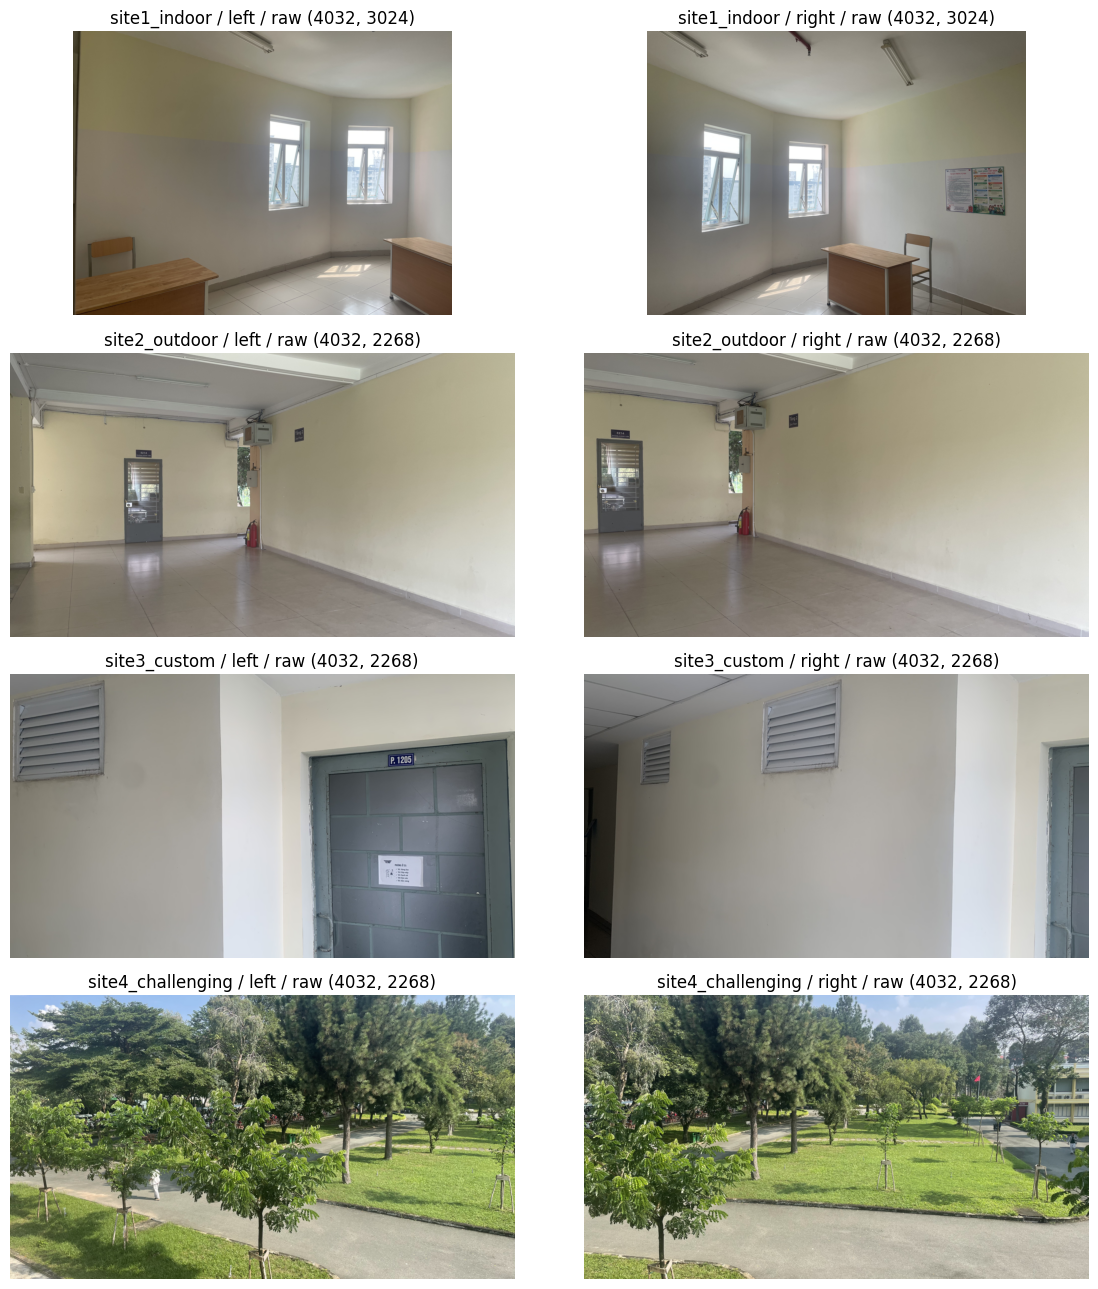

In [8]:
table(['Site', 'Địa điểm', 'Đặc điểm', 'Lý do chọn', 'Ánh sáng'], [
    [s['id'],s['location'],s['features'],s['reason'],s['lighting']] for s in team['sites']])
from report import show_dataset
show_dataset(ROOT)


## 3.7 Kế hoạch GPU
Đây là kế hoạch đề xuất để TV1/TV2 duyệt, chưa phải kết quả GPU.

| Stage | Ánh xạ V1 | Tối ưu V2/V3 và rủi ro |
|---|---|---|
| Gray/blur | Grid 2D, mỗi thread 1 pixel; hai pass blur | Shared memory + halo; kiểm soát boundary và đồng bộ |
| FAST/NMS | Mỗi thread 1 pixel, pass NMS riêng; compact rồi top-K | Scan/compaction; divergence và thứ tự đầu ra ảnh hưởng tái lập |
| BRIEF | Mỗi thread 1 keypoint ở V1 | Thử warp/keypoint; đọc patch phân tán, xử lý biên |
| BF Hamming | Mỗi thread 1 query, quét train và lấy best/second | Tiling train + `__popc`; chi phí reduction và occupancy |
| RANSAC | Mỗi block 1 hypothesis, thread đánh giá inlier | Reduction, tránh giả thuyết suy biến, RNG xác định; kiểm tra sai số float |
| Warp/blend | Mỗi thread 1 pixel canvas | Texture sampling, feathering; canvas lớn và truy cập nguồn phân tán |

Ba hướng tối ưu chính: shared-memory tiling cho blur/matching; scan/compaction cho keypoints; texture sampling và hai stream frontend. Chỉ chọn sau khi đối chiếu kết quả GPU với V0, đo kernel cùng H2D/D2H bằng CUDA Events và dùng Nsight xác định giới hạn thực tế. Các stage đứng đầu bảng profiling ở 3.5 được ưu tiên trước.

## Kiểm tra trước khi nộp
- Đã lưu output, bảng timing, biểu đồ và panorama từ các lần chạy thật trên máy được ghi ở 3.5.
- Chạy lại Run all trên Colab; số đo Windows không đại diện cho CPU Colab.
- Vai trò đã xác nhận: TV1 Trần Nguyễn Minh Quân, TV2 Vũ Trần Phúc, TV3 Nguyễn Hữu Khánh Hưng.
- Thay fixture bằng cặp synthetic chính thức khi nhận được, cập nhật provenance/chiều H rồi chạy lại.
- Kiểm tra tiêu chí registered sites/outdoor và quyền truy cập Drive; upload raw + prepared + synthetic.
- TV1/TV2 duyệt mô tả thuật toán và các giới hạn V0. Chưa có refit/feathering thực sự trong backend hiện tại.
